# B14 – Phát Hiện Tấn Công Mạng Bằng Naive Bayes
## Phân Loại Nhị Phân – Dataset CICMAL2017

## 1. Import Thư Viện

In [1]:
# ── Thư viện cơ bản ──────────────────────────────────────────────────────────
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── scikit-learn ─────────────────────────────────────────────────────────────
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (accuracy_score, brier_score_loss,
                             classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.naive_bayes import BernoulliNB, GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (MinMaxScaler, PowerTransformer,
                                   StandardScaler)

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

print("✅ Import xong!")
print("   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.")


✅ Import xong!
   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.


## 2. Cấu Hình Đường Dẫn & Tham Số

In [2]:
# ════════════════════════════════════════════════════════════════════
#  CẤU HÌNH
# ════════════════════════════════════════════════════════════════════
# ==========================
# ĐƯỜNG DẪN DATASET
# ==========================
ROOT_DIR = Path.cwd()
CANDIDATES = [
    ROOT_DIR.parent / "Dataset" / "category_CICMAL2017_dataset.csv",
    ROOT_DIR / "Dataset" / "category_CICMAL2017_dataset.csv",
]
CSV_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])

# ==========================
# NHÃN (LABELS)
# ==========================
LABEL_COL = "Binary Label"          # 0 = Benign, 1 = Malware
TARGET_NAMES = ["Benign", "Malware"]

# Cột định danh và nhãn đa lớp — không dùng làm đặc trưng
META_COLS = ["Flow ID", "Source IP", "Destination IP", "Timestamp", "Cat_Label"]

# ==========================
# CHIA DỮ LIỆU & TÁI LẬP
# ==========================
SEED = 42          # seed cố định để kết quả tái lập được
TEST_SIZE = 0.3    # 70% train / 30% test
CV_FOLDS = 5       # số fold của cross-validation

# ==========================
# KHÔNG GIAN SIÊU THAM SỐ
# ==========================
# var_smoothing: lượng cộng thêm vào phương sai của GaussianNB, tính theo
# tỷ lệ với phương sai lớn nhất trong các đặc trưng. Mặc định của sklearn
# là 1e-9 — bài này sẽ cho thấy giá trị mặc định đó thường quá nhỏ.
VS_GRID = [1e-11, 1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1, 1.0]

# Ngưỡng tương quan để coi hai đặc trưng là "trùng lặp thông tin"
CORR_THR = 0.95

# ==========================
# NHẬN XÉT IN KÈM TỪNG PHẦN
# ==========================
VARIANTS_COMMENT = (
    "\nNhận xét: với tham số mặc định, GaussianNB cho kết quả TỆ NHẤT "
    "(F1 ≈ 0,54–0,59)\n"
    "trong khi MultinomialNB đạt ≈ 0,97 và BernoulliNB ≈ 0,89. Đây là điều đáng\n"
    "ngạc nhiên vì các đặc trưng ở đây là số liên tục — đúng kiểu dữ liệu mà\n"
    "GaussianNB được thiết kế cho. Hai điểm cần điều tra:\n"
    "  (1) vì sao GaussianNB yếu đến vậy → phần A3 và A4;\n"
    "  (2) vì sao chuẩn hóa Z-score lại LÀM GIẢM F1 của GaussianNB, dù về lý\n"
    "      thuyết thuật toán này bất biến với phép co giãn tuyến tính → phần A3.")
VS_COMMENT = (
    "\nNhận xét: nâng var_smoothing từ 1e-9 lên 0,01 đưa F1 từ 0,54 lên 0,75 —\n"
    "cải thiện hơn 0,2 chỉ bằng một siêu tham số mà nhiều tài liệu không nhắc\n"
    "tới. Điều này khẳng định chẩn đoán: vấn đề không phải bản thân GaussianNB\n"
    "mà là phương sai trong lớp quá nhỏ ở một số đặc trưng. Tuy vậy 0,75 vẫn\n"
    "thấp hơn MultinomialNB (0,97), nên còn một nguyên nhân khác — xem A4.")
SKEW_COMMENT = (
    "\nNhận xét: 58 trong 72 đặc trưng có |độ lệch| > 2 và giá trị lớn nhất tới\n"
    "124,6 — dữ liệu lưu lượng mạng lệch cực mạnh, hoàn toàn không phải phân\n"
    "phối chuẩn. Đây chính là nguyên nhân thứ hai. Sau PowerTransformer, trung\n"
    "vị độ lệch giảm từ 7,42 xuống 0,86 và F1 nhảy từ 0,75 lên 0,97 — ngang\n"
    "bằng MultinomialNB. Bài học: với Naive Bayes, công sức bỏ vào việc làm cho\n"
    "dữ liệu khớp giả định của mô hình có giá trị hơn nhiều so với việc dò\n"
    "siêu tham số.")
CORR_COMMENT = (
    "\nNhận xét: chỉ 20 trong 2.556 cặp đặc trưng có |r| > 0,95, nhưng tồn tại\n"
    "cặp tương quan 1,0 — tức hai đặc trưng trùng lặp hoàn toàn, bị mô hình đếm\n"
    "bằng chứng hai lần. Loại 18 đặc trưng còn 54 vẫn giữ nguyên hiệu năng, cho\n"
    "thấy các đặc trưng đó không mang thêm thông tin. Lưu ý: con số ở đây đo\n"
    "trên tập test nên chỉ dùng để CHẨN ĐOÁN; việc quyết định có dùng bộ lọc\n"
    "trong mô hình cuối sẽ làm ở A7 bằng tập validation.")
CALIB_COMMENT = (
    "\nNhận xét: hơn 97% mẫu test bị gán xác suất dưới 1% hoặc trên 99% — mô\n"
    "hình gần như luôn \"rất chắc chắn\". Đó là hệ quả trực tiếp của việc nhân\n"
    "dồn xác suất của các đặc trưng không thực sự độc lập. Hiệu chỉnh isotonic\n"
    "kéo Brier từ 0,0341 xuống 0,0232 mà không làm giảm AUC. Với một SOC cần\n"
    "sắp thứ tự ưu tiên cảnh báo theo mức độ nghi ngờ, bước này là bắt buộc.")
FINAL_COMMENT = (
    "\nNhận xét: tinh chỉnh ngưỡng chỉ thêm được chút ít vì xác suất quá cực\n"
    "đoan — gần như không có mẫu nào nằm giữa để ngưỡng tạo khác biệt. Random\n"
    "Forest vẫn cao hơn rõ (F1 0,995 so với 0,975). Nhưng hãy nhìn thời gian\n"
    "huấn luyện: Naive Bayes nhanh hơn khoảng hai bậc độ lớn. Đó là lý do thuật\n"
    "toán này vẫn được dùng làm baseline đầu tiên và cho các hệ cần huấn luyện\n"
    "lại liên tục trên dữ liệu mới.")
KFOLD_COMMENT = (
    "\nNhận xét: độ lệch chuẩn rất nhỏ → kết quả ổn định. F1 trung bình qua\n"
    "cross-validation cao hơn một lần chia đơn lẻ ở A7, phần vì pipeline có\n"
    "thêm VarianceThreshold loại bỏ các đặc trưng trở thành hằng số trong\n"
    "từng fold.")

print("✅ Cấu hình xong!")
print(f"   Nhãn      → {LABEL_COL} (0 = {TARGET_NAMES[0]}, 1 = {TARGET_NAMES[1]})")
print(f"   Test size → {TEST_SIZE*100:.0f}%  |  SEED = {SEED}  |  CV folds = {CV_FOLDS}")
print(f"   VS_GRID   → {VS_GRID}")
print(f"   CORR_THR  → {CORR_THR}")
print(f"   Dataset   → {CSV_PATH}")


✅ Cấu hình xong!
   Nhãn      → Binary Label (0 = Benign, 1 = Malware)
   Test size → 30%  |  SEED = 42  |  CV folds = 5
   VS_GRID   → [1e-11, 1e-09, 1e-07, 1e-05, 0.001, 0.01, 0.1, 1.0]
   CORR_THR  → 0.95
   Dataset   → C:\Desktop\VANN\BÀI THỰC HÀNH C07\CV4.1\CV4.1\Dataset\category_CICMAL2017_dataset.csv


## 3. Hàm Tiện Ích Dùng Chung

In [3]:
# ════════════════════════════════════════════════════════════════════════════
# HÀM TIỀN XỬ LÝ DỮ LIỆU
# ════════════════════════════════════════════════════════════════════════════
def clean_numeric(df, label_col, drop_cols=(), keep_cols=None):
    """Làm sạch DataFrame và trả về ma trận đặc trưng CHƯA biến đổi:
      1. Chỉ giữ cột số, loại cột meta và cột nhãn
      2. Thay Inf / -Inf → NaN
      3. Điền giá trị thiếu bằng median
      4. Loại cột phương sai = 0

    keep_cols: nếu truyền vào thì lấy đúng danh sách cột đó thay vì tự chọn.
    Dùng cho tập held-out — tập này buộc phải có đúng bộ đặc trưng của tập train.
    """
    df = df.copy()
    df.columns = df.columns.str.strip()
    drop = [c for c in drop_cols if c in df.columns]
    feats = [c for c in df.select_dtypes(include=np.number).columns
             if c not in drop and c != label_col]

    X = df[feats].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(X.median(), inplace=True)

    if keep_cols is not None:
        return X[list(keep_cols)], []

    zero_var = X.columns[X.var() == 0].tolist()
    X.drop(columns=zero_var, inplace=True)
    return X, zero_var


# ════════════════════════════════════════════════════════════════════════════
# BỘ LỌC ĐẶC TRƯNG TƯƠNG QUAN CAO
# ════════════════════════════════════════════════════════════════════════════
# Naive Bayes giả định các đặc trưng ĐỘC LẬP với nhau khi đã biết nhãn. Hai
# đặc trưng tương quan gần như hoàn hảo sẽ bị mô hình đếm bằng chứng HAI LẦN,
# khiến xác suất bị đẩy về 0 hoặc 1. Bộ lọc này giữ lại một đặc trưng trong
# mỗi cặp có |tương quan| vượt ngưỡng.
#
# Viết dưới dạng transformer của scikit-learn để có thể đặt vào Pipeline —
# nhờ đó khi chạy cross-validation ở phần A8, bộ lọc được fit lại trên từng
# fold thay vì dùng kết quả tính trên toàn bộ dữ liệu (tránh rò rỉ).
class CorrelationFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.95):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        C = np.nan_to_num(np.abs(np.corrcoef(X, rowvar=False)))
        upper = np.triu(C, k=1)                      # chỉ xét tam giác trên
        drop = {int(j) for _, j in zip(*np.where(upper > self.threshold))}
        self.keep_ = [i for i in range(X.shape[1]) if i not in drop]
        self.n_dropped_ = X.shape[1] - len(self.keep_)
        self.n_pairs_ = int((upper > self.threshold).sum())
        self.max_corr_ = float(upper.max())
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.keep_]


# ════════════════════════════════════════════════════════════════════════════
# HÀM ĐÁNH GIÁ MỘT MÔ HÌNH
# ════════════════════════════════════════════════════════════════════════════
# Ngoài các chỉ số quen thuộc, bài này thêm Brier score — trung bình bình
# phương sai lệch giữa xác suất dự đoán và nhãn thật. Brier càng NHỎ càng tốt.
# Chỉ số này cần thiết vì Naive Bayes nổi tiếng cho xác suất rất lệch.
def evaluate(y_true, y_pred, y_score, name=""):
    return {
        "model": name,
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "rec": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
        "brier": brier_score_loss(y_true, y_score),
    }


print("✅ Đã định nghĩa clean_numeric(), CorrelationFilter(), evaluate()")


✅ Đã định nghĩa clean_numeric(), CorrelationFilter(), evaluate()


---
# Xây Dựng Mô Hình Naive Bayes

> **Bài toán:** Dự đoán một luồng mạng là **Benign (0)** hay **Malware (1)**
>
> **Ý tưởng của Naive Bayes:** tính xác suất một luồng thuộc mỗi lớp theo định lý Bayes, với giả định các đặc trưng độc lập nhau khi đã biết lớp. Nhờ giả định đó, mô hình chỉ cần đếm thống kê từng đặc trưng một lần — huấn luyện gần như tức thì.
>
> **Điều bài này tập trung vào:** giả định của Naive Bayes bị vi phạm ở đâu, và sửa được bao nhiêu phần.

### A1. Tải & Tiền Xử Lý Dữ Liệu

In [4]:
print("═" * 70)
print("TẢI DỮ LIỆU CICMAL2017")
print("═" * 70)

df = pd.read_csv(CSV_PATH, low_memory=False)
y = df[LABEL_COL].astype(int).values

print(f"Shape gốc : {df.shape}")
print(f"\nPhân phối nhãn:")
print(f"   {TARGET_NAMES[0]}(0) : {int((y == 0).sum()):,}")
print(f"   {TARGET_NAMES[1]}(1) : {int((y == 1).sum()):,}")
print(f"   Tỷ lệ mã độc  : {(y == 1).mean()*100:.2f}%")

X_raw, zero_var = clean_numeric(df, LABEL_COL, META_COLS)
print(f"\n✅ Sau tiền xử lý:")
print(f"   Loại {len(zero_var)} cột phương sai = 0")
print(f"   Số đặc trưng : {X_raw.shape[1]}")
print(f"   Số mẫu       : {X_raw.shape[0]:,}")

# ── Chia train/test TRƯỚC, biến đổi SAU ─────────────────────────────────────
# Mọi phép biến đổi (scaler, PowerTransformer, bộ lọc tương quan) chỉ được
# fit trên tập train. Nếu fit trên toàn bộ dữ liệu thì thông tin của tập test
# đã lọt vào mô hình — rò rỉ dữ liệu.
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(
    X_raw.values, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

# Hai biểu diễn dữ liệu cần cho ba biến thể Naive Bayes ở phần A2:
scaler = StandardScaler().fit(X_tr_raw)           # cho GaussianNB
X_tr, X_te = scaler.transform(X_tr_raw), scaler.transform(X_te_raw)

minmax = MinMaxScaler().fit(X_tr_raw)             # cho Bernoulli / Multinomial
X_tr_mm = minmax.transform(X_tr_raw)
# MultinomialNB không nhận giá trị âm; mẫu test nằm ngoài khoảng của tập
# train có thể bị đưa về số âm nên phải chặn lại ở 0.
X_te_mm = np.clip(minmax.transform(X_te_raw), 0, None)

print(f"\n📦 Chia tập dữ liệu (stratified "
      f"{int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)}):")
print(f"   Train : {X_tr.shape[0]:,} mẫu ({int(y_tr.sum()):,} dương)")
print(f"   Test  : {X_te.shape[0]:,} mẫu ({int(y_te.sum()):,} dương)")


══════════════════════════════════════════════════════════════════════
TẢI DỮ LIỆU CICMAL2017
══════════════════════════════════════════════════════════════════════


Shape gốc : (22192, 86)

Phân phối nhãn:
   Benign(0) : 5,039
   Malware(1) : 17,153
   Tỷ lệ mã độc  : 77.29%

✅ Sau tiền xử lý:
   Loại 8 cột phương sai = 0
   Số đặc trưng : 72
   Số mẫu       : 22,192

📦 Chia tập dữ liệu (stratified 70/30):
   Train : 15,534 mẫu (12,007 dương)
   Test  : 6,658 mẫu (5,146 dương)


### A2. Ba Biến Thể Naive Bayes: Gaussian, Bernoulli, Multinomial

                                       acc    prec     rec      f1     auc  \
model                                                                        
GaussianNB (dữ liệu thô)            0.5452  0.9894  0.4161  0.5858  0.9739   
GaussianNB (Z-score)                0.5119  0.9912  0.3717  0.5407  0.9733   
BernoulliNB (MinMax, binarize=0.5)  0.8396  0.9766  0.8119  0.8867  0.8929   
MultinomialNB (MinMax)              0.9515  0.9649  0.9726  0.9687  0.9669   

                                     brier  
model                                       
GaussianNB (dữ liệu thô)            0.4516  
GaussianNB (Z-score)                0.4861  
BernoulliNB (MinMax, binarize=0.5)  0.1406  
MultinomialNB (MinMax)              0.0494  

GaussianNB: thô F1 = 0.5858 | Z-score F1 = 0.5407  → chênh -0.0451

Nhận xét: với tham số mặc định, GaussianNB cho kết quả TỆ NHẤT (F1 ≈ 0,54–0,59)
trong khi MultinomialNB đạt ≈ 0,97 và BernoulliNB ≈ 0,89. Đây là điều đáng
ngạc nhiên vì các đặc trưng ở đây là 

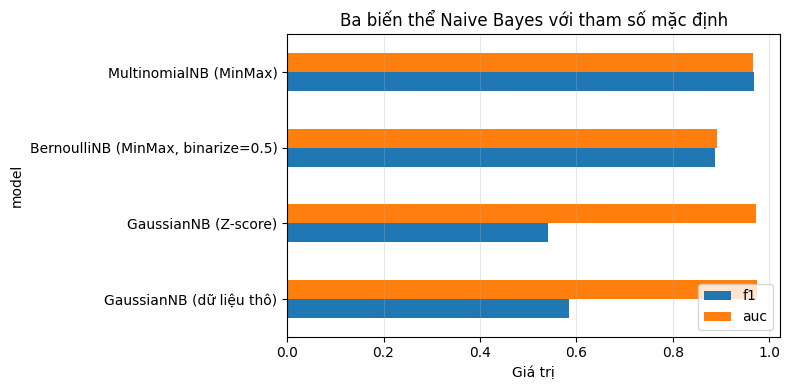

In [5]:
# Naive Bayes dựa trên định lý Bayes cùng một giả định đơn giản hóa mạnh:
# các đặc trưng ĐỘC LẬP với nhau khi đã biết nhãn. Nhờ đó xác suất hợp của
# nhiều đặc trưng trở thành phép nhân các xác suất lẻ, và mô hình chỉ cần
# đếm thống kê từng đặc trưng một lần — huấn luyện cực nhanh.
#
# Ba biến thể khác nhau ở chỗ mô hình hóa P(đặc trưng | lớp) như thế nào:
#   GaussianNB    – giả định mỗi đặc trưng theo phân phối chuẩn trong từng lớp
#   BernoulliNB   – giả định đặc trưng nhị phân (có / không), cần binarize
#   MultinomialNB – giả định đặc trưng là số đếm không âm, cần đưa về [0, 1]
rows = []

g_raw = GaussianNB().fit(X_tr_raw, y_tr)
rows.append(evaluate(y_te, g_raw.predict(X_te_raw),
                     g_raw.predict_proba(X_te_raw)[:, 1], "GaussianNB (dữ liệu thô)"))

g_std = GaussianNB().fit(X_tr, y_tr)
rows.append(evaluate(y_te, g_std.predict(X_te),
                     g_std.predict_proba(X_te)[:, 1], "GaussianNB (Z-score)"))

bnb = BernoulliNB(binarize=0.5).fit(X_tr_mm, y_tr)
rows.append(evaluate(y_te, bnb.predict(X_te_mm),
                     bnb.predict_proba(X_te_mm)[:, 1], "BernoulliNB (MinMax, binarize=0.5)"))

mnb = MultinomialNB().fit(X_tr_mm, y_tr)
rows.append(evaluate(y_te, mnb.predict(X_te_mm),
                     mnb.predict_proba(X_te_mm)[:, 1], "MultinomialNB (MinMax)"))

var_df = pd.DataFrame(rows).set_index("model").round(4)
print(var_df[["acc", "prec", "rec", "f1", "auc", "brier"]])
print(f"\nGaussianNB: thô F1 = {rows[0]['f1']:.4f} | Z-score F1 = {rows[1]['f1']:.4f}"
      f"  → chênh {rows[1]['f1'] - rows[0]['f1']:+.4f}")
print(VARIANTS_COMMENT)

ax = var_df[["f1", "auc"]].plot.barh(figsize=(8, 4))
ax.set_xlabel("Giá trị")
ax.set_title("Ba biến thể Naive Bayes với tham số mặc định")
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A3. var_smoothing – Siêu Tham Số Quyết Định Của GaussianNB

                  acc    prec     rec      f1     auc
var_smoothing                                        
1.000000e-11   0.4956  0.9928  0.3500  0.5175  0.9733
1.000000e-09   0.5119  0.9912  0.3717  0.5407  0.9733
1.000000e-07   0.5303  0.9912  0.3958  0.5658  0.9734
1.000000e-05   0.5575  0.9889  0.4324  0.6017  0.9740
1.000000e-03   0.6373  0.9910  0.5356  0.6953  0.9733
1.000000e-02   0.6886  0.9882  0.6044  0.7500  0.9723
1.000000e-01   0.6236  0.9853  0.5208  0.6814  0.9662
1.000000e+00   0.4728  0.9750  0.3263  0.4889  0.9579

→ var_smoothing tốt nhất trên dữ liệu Z-score: 0.01  (F1 = 0.7500)
→ So với mặc định 1e-09 (F1 = 0.5407): +0.2093

Nhận xét: nâng var_smoothing từ 1e-9 lên 0,01 đưa F1 từ 0,54 lên 0,75 —
cải thiện hơn 0,2 chỉ bằng một siêu tham số mà nhiều tài liệu không nhắc
tới. Điều này khẳng định chẩn đoán: vấn đề không phải bản thân GaussianNB
mà là phương sai trong lớp quá nhỏ ở một số đặc trưng. Tuy vậy 0,75 vẫn
thấp hơn MultinomialNB (0,97), nên còn một nguyên nhâ

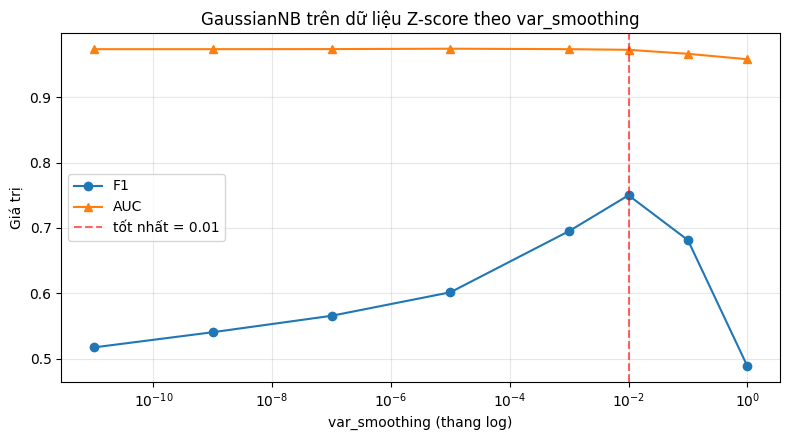

In [6]:
# Về lý thuyết, GaussianNB BẤT BIẾN với phép co giãn tuyến tính từng đặc
# trưng: nó chỉ ước lượng trung bình và phương sai của mỗi đặc trưng trong
# mỗi lớp. Nhưng kết quả ở A2 cho thấy chuẩn hóa lại làm thay đổi F1 rất
# mạnh. Nguyên nhân nằm ở var_smoothing.
#
# scikit-learn cộng thêm vào phương sai mỗi đặc trưng một lượng
#     var_smoothing × (phương sai LỚN NHẤT trong toàn bộ các đặc trưng)
# Trên dữ liệu thô, phương sai lớn nhất có thể tới hàng tỷ nên lượng cộng
# thêm rất đáng kể. Sau khi chuẩn hóa, mọi phương sai bằng 1 nên lượng cộng
# thêm chỉ còn 1e-9 — gần như bằng 0. Khi đó đặc trưng nào có phương sai
# trong lớp xấp xỉ 0 sẽ tạo ra mật độ Gauss cực nhọn, đẩy xác suất về 0 hoặc
# 1 và làm mô hình sụp đổ.
rows = []
for v in VS_GRID:
    g = GaussianNB(var_smoothing=v).fit(X_tr, y_tr)
    rows.append(evaluate(y_te, g.predict(X_te), g.predict_proba(X_te)[:, 1], v))

vs_df = pd.DataFrame(rows).set_index("model").round(4)
vs_df.index.name = "var_smoothing"
print(vs_df[["acc", "prec", "rec", "f1", "auc"]])

vs_best = vs_df["f1"].idxmax()
print(f"\n→ var_smoothing tốt nhất trên dữ liệu Z-score: {vs_best:g}"
      f"  (F1 = {vs_df.loc[vs_best, 'f1']:.4f})")
print(f"→ So với mặc định 1e-09 (F1 = {vs_df.loc[1e-9, 'f1']:.4f}): "
      f"{vs_df.loc[vs_best, 'f1'] - vs_df.loc[1e-9, 'f1']:+.4f}")
print(VS_COMMENT)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(vs_df.index, vs_df["f1"], marker="o", label="F1")
ax.semilogx(vs_df.index, vs_df["auc"], marker="^", label="AUC")
ax.axvline(vs_best, color="red", ls="--", alpha=.6,
           label=f"tốt nhất = {vs_best:g}")
ax.set_xlabel("var_smoothing (thang log)")
ax.set_ylabel("Giá trị")
ax.set_title("GaussianNB trên dữ liệu Z-score theo var_smoothing")
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()


### A4. Kiểm Tra Giả Định Phân Phối Chuẩn

Độ lệch tuyệt đối của 72 đặc trưng (dữ liệu Z-score):
   trung vị      : 7.42
   lớn nhất      : 124.6
   số đặc trưng có |độ lệch| > 2  : 58
   số đặc trưng có |độ lệch| > 10 : 32



Sau PowerTransformer:
   trung vị      : 0.86
   số đặc trưng có |độ lệch| > 2  : 26



GaussianNB trên dữ liệu PowerTransformer:
                   f1     auc   brier
var_smoothing                        
1.000000e-11   0.9179  0.9771  0.1174
1.000000e-09   0.9288  0.9762  0.1019
1.000000e-07   0.9442  0.9743  0.0799
1.000000e-05   0.9602  0.9724  0.0562
1.000000e-03   0.9719  0.9675  0.0422
1.000000e-02   0.9743  0.9668  0.0341
1.000000e-01   0.9741  0.9691  0.0316
1.000000e+00   0.9503  0.9710  0.0672

→ Z-score            : F1 = 0.7500 (var_smoothing = 0.01)
→ PowerTransformer   : F1 = 0.9743 (var_smoothing = 0.01)
→ Biểu diễn dùng cho các phần sau: PowerTransformer với var_smoothing = 0.01

Nhận xét: 58 trong 72 đặc trưng có |độ lệch| > 2 và giá trị lớn nhất tới
124,6 — dữ liệu lưu lượng mạng lệch cực mạnh, hoàn toàn không phải phân
phối chuẩn. Đây chính là nguyên nhân thứ hai. Sau PowerTransformer, trung
vị độ lệch giảm từ 7,42 xuống 0,86 và F1 nhảy từ 0,75 lên 0,97 — ngang
bằng MultinomialNB. Bài học: với Naive Bayes, công sức bỏ vào việc làm cho
dữ liệu khớp giả 

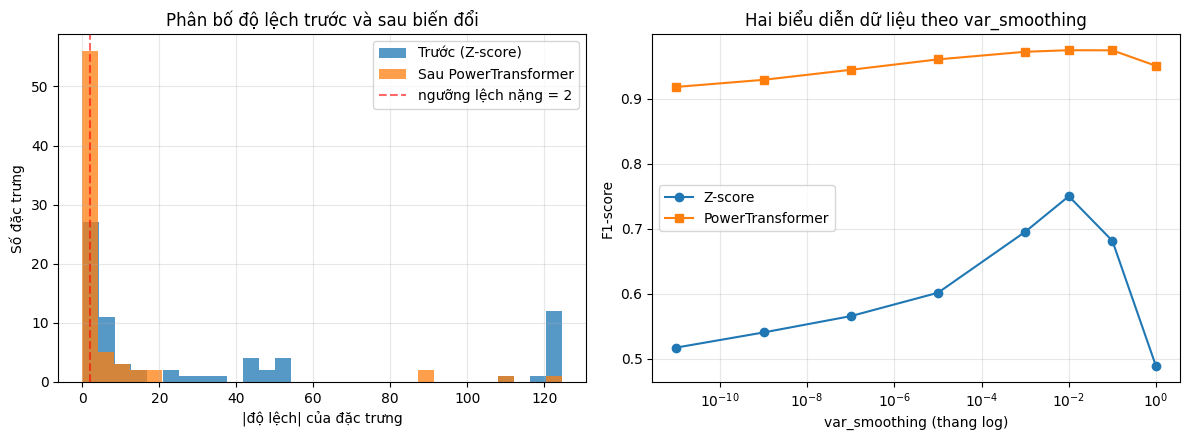

In [7]:
# GaussianNB giả định mỗi đặc trưng theo phân phối CHUẨN trong từng lớp.
# Ta kiểm tra giả định đó bằng độ lệch (skewness): phân phối chuẩn có độ
# lệch 0, |độ lệch| > 2 là lệch nặng.
#
# Độ lệch bất biến với phép co giãn tuyến tính, nên tính trên dữ liệu đã
# chuẩn hóa cho kết quả giống hệt dữ liệu thô nhưng không bị tràn số học.
skew_before = pd.DataFrame(X_tr).skew().abs()
print(f"Độ lệch tuyệt đối của {X_tr.shape[1]} đặc trưng (dữ liệu Z-score):")
print(f"   trung vị      : {skew_before.median():.2f}")
print(f"   lớn nhất      : {skew_before.max():.1f}")
print(f"   số đặc trưng có |độ lệch| > 2  : {int((skew_before > 2).sum())}")
print(f"   số đặc trưng có |độ lệch| > 10 : {int((skew_before > 10).sum())}")

# PowerTransformer (Yeo-Johnson) tìm một phép biến đổi lũy thừa cho từng đặc
# trưng sao cho kết quả gần phân phối chuẩn nhất, rồi chuẩn hóa về N(0, 1).
# Khác với log, Yeo-Johnson xử lý được cả giá trị âm và giá trị 0.
pt = PowerTransformer(method="yeo-johnson", standardize=True).fit(X_tr_raw)
X_tr_pt, X_te_pt = pt.transform(X_tr_raw), pt.transform(X_te_raw)

skew_after = pd.DataFrame(X_tr_pt).skew().abs()
print(f"\nSau PowerTransformer:")
print(f"   trung vị      : {skew_after.median():.2f}")
print(f"   số đặc trưng có |độ lệch| > 2  : {int((skew_after > 2).sum())}")

rows = []
for v in VS_GRID:
    g = GaussianNB(var_smoothing=v).fit(X_tr_pt, y_tr)
    rows.append(evaluate(y_te, g.predict(X_te_pt),
                         g.predict_proba(X_te_pt)[:, 1], v))
pt_df = pd.DataFrame(rows).set_index("model").round(4)
pt_df.index.name = "var_smoothing"
print(f"\nGaussianNB trên dữ liệu PowerTransformer:")
print(pt_df[["f1", "auc", "brier"]])

vs_best_pt = pt_df["f1"].idxmax()
f1_std, f1_pt = vs_df.loc[vs_best, "f1"], pt_df.loc[vs_best_pt, "f1"]
print(f"\n→ Z-score            : F1 = {f1_std:.4f} (var_smoothing = {vs_best:g})")
print(f"→ PowerTransformer   : F1 = {f1_pt:.4f} (var_smoothing = {vs_best_pt:g})")

# Chọn biểu diễn tốt hơn làm biểu diễn cuối cho các phần sau
if f1_pt >= f1_std:
    REPR, X_tr_f, X_te_f, VS_F, tf_final = "PowerTransformer", X_tr_pt, X_te_pt, vs_best_pt, pt
else:
    REPR, X_tr_f, X_te_f, VS_F, tf_final = "Z-score", X_tr, X_te, vs_best, scaler
print(f"→ Biểu diễn dùng cho các phần sau: {REPR} "
      f"với var_smoothing = {VS_F:g}")
print(SKEW_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(skew_before, bins=30, alpha=.75, label="Trước (Z-score)")
axes[0].hist(skew_after, bins=30, alpha=.75, label="Sau PowerTransformer")
axes[0].axvline(2, color="red", ls="--", alpha=.6, label="ngưỡng lệch nặng = 2")
axes[0].set_xlabel("|độ lệch| của đặc trưng")
axes[0].set_ylabel("Số đặc trưng")
axes[0].set_title("Phân bố độ lệch trước và sau biến đổi")
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].semilogx(vs_df.index, vs_df["f1"], marker="o", label="Z-score")
axes[1].semilogx(pt_df.index, pt_df["f1"], marker="s", label="PowerTransformer")
axes[1].set_xlabel("var_smoothing (thang log)")
axes[1].set_ylabel("F1-score")
axes[1].set_title("Hai biểu diễn dữ liệu theo var_smoothing")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A5. Kiểm Tra Giả Định Độc Lập Điều Kiện

Số cặp đặc trưng : 2,556
Số cặp có |r| > 0.95 : 20
Tương quan lớn nhất giữa hai đặc trưng khác nhau: 1.0000

Loại 18 đặc trưng, còn lại 54

                                      acc    prec     rec      f1     auc  \
model                                                                       
Toàn bộ 72 đặc trưng               0.9603  0.9775  0.9710  0.9743  0.9668   
Sau lọc tương quan (54 đặc trưng)  0.9769  0.9756  0.9949  0.9852  0.9719   

                                    brier  
model                                      
Toàn bộ 72 đặc trưng               0.0341  
Sau lọc tương quan (54 đặc trưng)  0.0230  

Nhận xét: chỉ 20 trong 2.556 cặp đặc trưng có |r| > 0,95, nhưng tồn tại
cặp tương quan 1,0 — tức hai đặc trưng trùng lặp hoàn toàn, bị mô hình đếm
bằng chứng hai lần. Loại 18 đặc trưng còn 54 vẫn giữ nguyên hiệu năng, cho
thấy các đặc trưng đó không mang thêm thông tin. Lưu ý: con số ở đây đo
trên tập test nên chỉ dùng để CHẨN ĐOÁN; việc quyết định có dùng bộ lọc
trong mô

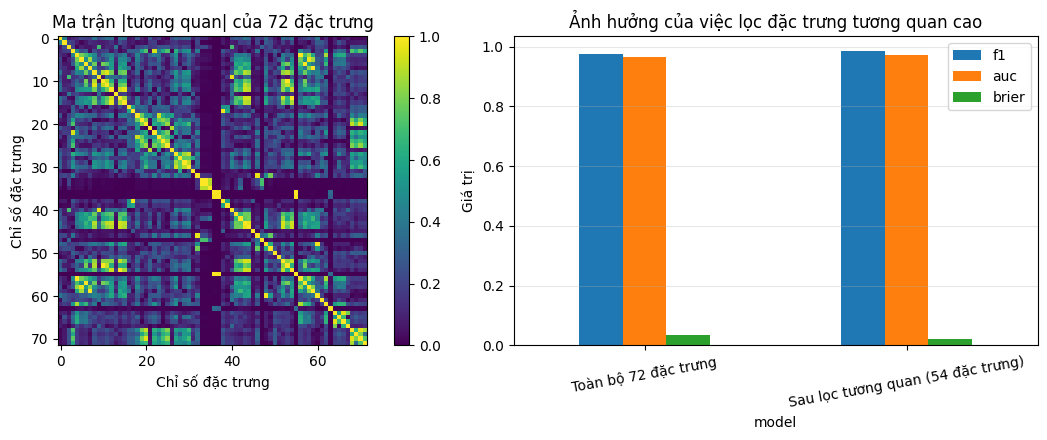

In [8]:
# Giả định "độc lập điều kiện" là chỗ chữ NAIVE trong tên thuật toán. Dữ
# liệu thật hầu như luôn vi phạm nó. Ta đo mức vi phạm bằng cách đếm số cặp
# đặc trưng có |tương quan| vượt ngưỡng, rồi thử loại bớt và đo lại.
cf = CorrelationFilter(threshold=CORR_THR).fit(X_tr_f)
n_pairs_total = X_tr_f.shape[1] * (X_tr_f.shape[1] - 1) // 2

print(f"Số cặp đặc trưng : {n_pairs_total:,}")
print(f"Số cặp có |r| > {CORR_THR} : {cf.n_pairs_}")
print(f"Tương quan lớn nhất giữa hai đặc trưng khác nhau: {cf.max_corr_:.4f}")
print(f"\nLoại {cf.n_dropped_} đặc trưng, còn lại {len(cf.keep_)}")

X_tr_cf, X_te_cf = cf.transform(X_tr_f), cf.transform(X_te_f)
g_full = GaussianNB(var_smoothing=VS_F).fit(X_tr_f, y_tr)
g_cf = GaussianNB(var_smoothing=VS_F).fit(X_tr_cf, y_tr)

rows = [
    evaluate(y_te, g_full.predict(X_te_f), g_full.predict_proba(X_te_f)[:, 1],
             f"Toàn bộ {X_tr_f.shape[1]} đặc trưng"),
    evaluate(y_te, g_cf.predict(X_te_cf), g_cf.predict_proba(X_te_cf)[:, 1],
             f"Sau lọc tương quan ({len(cf.keep_)} đặc trưng)"),
]
corr_df = pd.DataFrame(rows).set_index("model").round(4)
print()
print(corr_df[["acc", "prec", "rec", "f1", "auc", "brier"]])
print(CORR_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
C = np.nan_to_num(np.abs(np.corrcoef(np.asarray(X_tr_f, dtype=float), rowvar=False)))
im = axes[0].imshow(C, cmap="viridis", vmin=0, vmax=1)
axes[0].set_title(f"Ma trận |tương quan| của {X_tr_f.shape[1]} đặc trưng")
axes[0].set_xlabel("Chỉ số đặc trưng")
axes[0].set_ylabel("Chỉ số đặc trưng")
plt.colorbar(im, ax=axes[0], fraction=.046)

corr_df[["f1", "auc", "brier"]].plot.bar(ax=axes[1], rot=10)
axes[1].set_title("Ảnh hưởng của việc lọc đặc trưng tương quan cao")
axes[1].set_ylabel("Giá trị")
axes[1].grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


### A6. Hiệu Chỉnh Xác Suất (Calibration) & Điểm Brier

Tỷ lệ mẫu test được gán xác suất < 1% hoặc > 99%: 97.43%
Brier score khi chưa hiệu chỉnh : 0.0341
Brier score sau hiệu chỉnh      : 0.0232



                         acc    prec     rec      f1     auc   brier
model                                                               
Chưa hiệu chỉnh       0.9603  0.9775  0.9710  0.9743  0.9668  0.0341
Isotonic calibration  0.9742  0.9730  0.9942  0.9835  0.9686  0.0232

Nhận xét: hơn 97% mẫu test bị gán xác suất dưới 1% hoặc trên 99% — mô
hình gần như luôn "rất chắc chắn". Đó là hệ quả trực tiếp của việc nhân
dồn xác suất của các đặc trưng không thực sự độc lập. Hiệu chỉnh isotonic
kéo Brier từ 0,0341 xuống 0,0232 mà không làm giảm AUC. Với một SOC cần
sắp thứ tự ưu tiên cảnh báo theo mức độ nghi ngờ, bước này là bắt buộc.


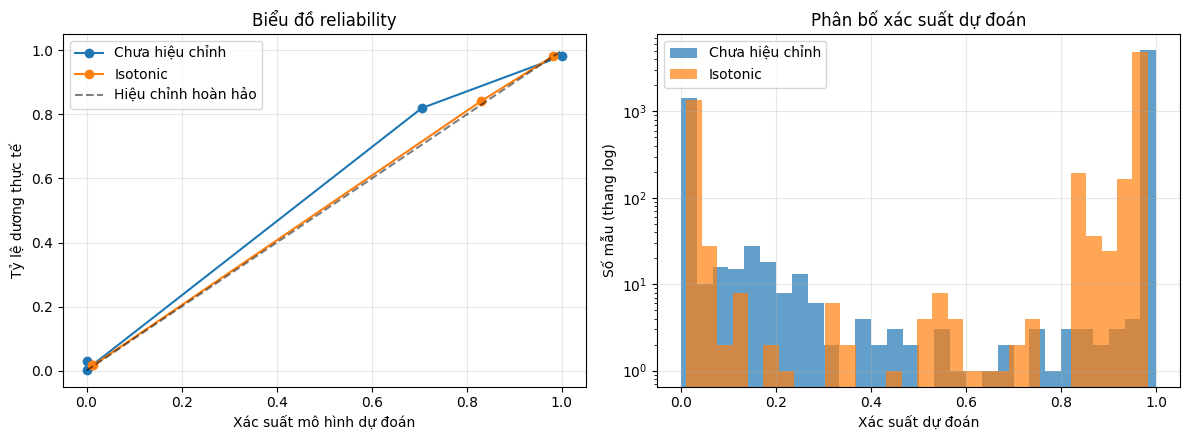

In [9]:
# Naive Bayes cho thứ hạng khá tốt (AUC cao) nhưng xác suất rất lệch: vì nhân
# dồn nhiều xác suất lẻ của các đặc trưng không thực sự độc lập, kết quả bị
# đẩy sát 0 hoặc 1. Mô hình "nói" 99% trong khi thực tế chỉ đúng 70%.
#
# Brier score đo trực tiếp sai lệch đó. Biểu đồ reliability vẽ tỷ lệ dương
# thực tế theo từng khoảng xác suất dự đoán — đường lý tưởng là đường chéo.
base = GaussianNB(var_smoothing=VS_F).fit(X_tr_f, y_tr)
p_uncal = base.predict_proba(X_te_f)[:, 1]

frac_extreme = ((p_uncal < 0.01) | (p_uncal > 0.99)).mean()
print(f"Tỷ lệ mẫu test được gán xác suất < 1% hoặc > 99%: {frac_extreme:.2%}")
print(f"Brier score khi chưa hiệu chỉnh : {brier_score_loss(y_te, p_uncal):.4f}")

# CalibratedClassifierCV học lại một hàm đơn điệu ánh xạ điểm của mô hình
# sang xác suất thật, dùng cross-validation nội bộ trên tập train.
cal = CalibratedClassifierCV(GaussianNB(var_smoothing=VS_F),
                             method="isotonic", cv=5)
cal.fit(X_tr_f, y_tr)
p_cal = cal.predict_proba(X_te_f)[:, 1]
print(f"Brier score sau hiệu chỉnh      : {brier_score_loss(y_te, p_cal):.4f}")

rows = [
    evaluate(y_te, base.predict(X_te_f), p_uncal, "Chưa hiệu chỉnh"),
    evaluate(y_te, cal.predict(X_te_f), p_cal, "Isotonic calibration"),
]
cal_df = pd.DataFrame(rows).set_index("model").round(4)
print()
print(cal_df[["acc", "prec", "rec", "f1", "auc", "brier"]])
print(CALIB_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for nm, p in [("Chưa hiệu chỉnh", p_uncal), ("Isotonic", p_cal)]:
    ft, mp = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    axes[0].plot(mp, ft, marker="o", label=nm)
axes[0].plot([0, 1], [0, 1], "k--", alpha=.5, label="Hiệu chỉnh hoàn hảo")
axes[0].set_xlabel("Xác suất mô hình dự đoán")
axes[0].set_ylabel("Tỷ lệ dương thực tế")
axes[0].set_title("Biểu đồ reliability")
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].hist(p_uncal, bins=30, alpha=.7, label="Chưa hiệu chỉnh")
axes[1].hist(p_cal, bins=30, alpha=.7, label="Isotonic")
axes[1].set_yscale("log")
axes[1].set_xlabel("Xác suất dự đoán")
axes[1].set_ylabel("Số mẫu (thang log)")
axes[1].set_title("Phân bố xác suất dự đoán")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A7. Chọn Tập Đặc Trưng, Ngưỡng Quyết Định & Mô Hình Cuối

Tách từ tập train: 12,427 mẫu để fit | 3,107 mẫu validation

F1 trên tập validation:
   Toàn bộ đặc trưng     : 0.9835
   Lọc tương quan        : 0.9828
→ Dùng bộ lọc tương quan: False
→ Số đặc trưng của mô hình cuối: 72

→ Ngưỡng tốt nhất trên validation: 0.35 (F1 = 0.9850; tại ngưỡng 0.50 chỉ đạt 0.9835)



                                               acc    prec     rec      f1  \
model                                                                        
GaussianNB (ngưỡng mặc định 0.50)           0.9603  0.9775  0.9710  0.9743   
GaussianNB (PowerTransformer, ngưỡng 0.35)  0.9611  0.9770  0.9726  0.9748   
Random Forest (200 cây)                     0.9923  0.9927  0.9975  0.9951   

                                            f1_macro     auc   brier  
model                                                                 
GaussianNB (ngưỡng mặc định 0.50)             0.9440  0.9668  0.0341  
GaussianNB (PowerTransformer, ngưỡng 0.35)    0.9449  0.9668  0.0341  
Random Forest (200 cây)                       0.9890  0.9947  0.0070  

Thời gian huấn luyện: Naive Bayes 23.9 ms | Random Forest 3565.5 ms  → nhanh hơn khoảng 149 lần

Confusion matrix Naive Bayes:  TN=1394  FP=118  FN=141  TP=5005
  FP = 118 cảnh báo giả | FN = 141 lần bỏ sót malware

              precision    recall  f

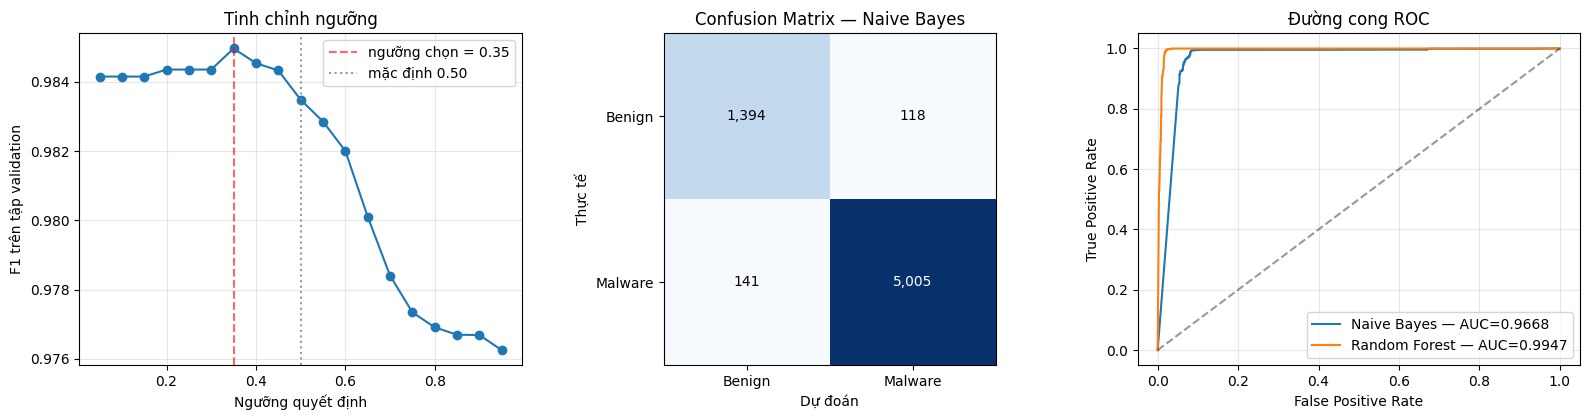

In [10]:
# Hai quyết định còn lại — dùng bộ lọc tương quan hay không, và chọn ngưỡng
# quyết định nào — phải được đưa ra trên dữ liệu MÔ HÌNH CHƯA THẤY, nhưng
# cũng KHÔNG ĐƯỢC dùng tập test. Nếu chọn theo điểm trên tập test thì tập
# test không còn là phép thử độc lập nữa.
# Vì vậy ta tách thêm một tập validation từ chính tập train.
X_a, X_v, y_a, y_v = train_test_split(X_tr_f, y_tr, test_size=0.2,
                                      random_state=SEED, stratify=y_tr)
print(f"Tách từ tập train: {X_a.shape[0]:,} mẫu để fit | "
      f"{X_v.shape[0]:,} mẫu validation")

# ── Quyết định 1: có dùng bộ lọc tương quan hay không ───────────────────────
pick = {}
for tag, use in [("Toàn bộ đặc trưng", False), ("Lọc tương quan", True)]:
    if use:
        c = CorrelationFilter(threshold=CORR_THR).fit(X_a)
        A, V = c.transform(X_a), c.transform(X_v)
    else:
        A, V = X_a, X_v
    g = GaussianNB(var_smoothing=VS_F).fit(A, y_a)
    pick[tag] = f1_score(y_v, g.predict(V), zero_division=0)

print("\nF1 trên tập validation:")
for k, v in pick.items():
    print(f"   {k:22s}: {v:.4f}")
USE_CF = pick["Lọc tương quan"] > pick["Toàn bộ đặc trưng"]
print(f"→ Dùng bộ lọc tương quan: {USE_CF}")

if USE_CF:
    c_val = CorrelationFilter(threshold=CORR_THR).fit(X_a)
    A, V = c_val.transform(X_a), c_val.transform(X_v)
    cf_final = CorrelationFilter(threshold=CORR_THR).fit(X_tr_f)
    X_tr_sel, X_te_sel = cf_final.transform(X_tr_f), cf_final.transform(X_te_f)
else:
    A, V = X_a, X_v
    cf_final = None
    X_tr_sel, X_te_sel = X_tr_f, X_te_f
print(f"→ Số đặc trưng của mô hình cuối: {X_tr_sel.shape[1]}")

# ── Quyết định 2: ngưỡng quyết định ─────────────────────────────────────────
# Ngưỡng mặc định 0.5 chỉ hợp lý khi xác suất đã được hiệu chỉnh tốt và hai
# lớp cân bằng. Với Naive Bayes thì cả hai điều đó đều không đúng.
g_val = GaussianNB(var_smoothing=VS_F).fit(A, y_a)
p_val = g_val.predict_proba(V)[:, 1]
THR_GRID = np.arange(0.05, 0.96, 0.05)
f1_by_thr = [f1_score(y_v, (p_val >= t).astype(int), zero_division=0)
             for t in THR_GRID]
THR = float(THR_GRID[int(np.argmax(f1_by_thr))])
print(f"\n→ Ngưỡng tốt nhất trên validation: {THR:.2f} "
      f"(F1 = {max(f1_by_thr):.4f}; tại ngưỡng 0.50 chỉ đạt "
      f"{f1_score(y_v, (p_val >= 0.5).astype(int), zero_division=0):.4f})")

# ── Mô hình cuối, huấn luyện lại trên toàn bộ tập train ────────────────────
final = GaussianNB(var_smoothing=VS_F).fit(X_tr_sel, y_tr)
p_final = final.predict_proba(X_te_sel)[:, 1]
y_pred = (p_final >= THR).astype(int)

nb_res = evaluate(y_te, y_pred, p_final,
                  f"GaussianNB ({REPR}, ngưỡng {THR:.2f})")
nb_res_05 = evaluate(y_te, (p_final >= 0.5).astype(int), p_final,
                     "GaussianNB (ngưỡng mặc định 0.50)")

# ── So sánh với Random Forest, kèm thời gian huấn luyện ────────────────────
t0 = time.perf_counter()
GaussianNB(var_smoothing=VS_F).fit(X_tr_sel, y_tr)
t_nb = time.perf_counter() - t0

rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
t0 = time.perf_counter()
rf.fit(X_tr_sel, y_tr)
t_rf = time.perf_counter() - t0
rf_score = rf.predict_proba(X_te_sel)[:, 1]
rf_res = evaluate(y_te, rf.predict(X_te_sel), rf_score, "Random Forest (200 cây)")

cmp_df = pd.DataFrame([nb_res_05, nb_res, rf_res]).set_index("model").round(4)
print()
print(cmp_df[["acc", "prec", "rec", "f1", "f1_macro", "auc", "brier"]])
print(f"\nThời gian huấn luyện: Naive Bayes {t_nb*1000:.1f} ms | "
      f"Random Forest {t_rf*1000:.1f} ms  → nhanh hơn khoảng "
      f"{t_rf/max(t_nb, 1e-9):.0f} lần")

cm = confusion_matrix(y_te, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion matrix Naive Bayes:  TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"  FP = {fp} cảnh báo giả | FN = {fn} lần bỏ sót {TARGET_NAMES[1].lower()}")
print("\n" + classification_report(y_te, y_pred, target_names=TARGET_NAMES,
                                    digits=4))
print(FINAL_COMMENT)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].plot(THR_GRID, f1_by_thr, marker="o")
axes[0].axvline(THR, color="red", ls="--", alpha=.6, label=f"ngưỡng chọn = {THR:.2f}")
axes[0].axvline(0.5, color="gray", ls=":", alpha=.8, label="mặc định 0.50")
axes[0].set_xlabel("Ngưỡng quyết định")
axes[0].set_ylabel("F1 trên tập validation")
axes[0].set_title("Tinh chỉnh ngưỡng")
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[1].text(j, i, f"{v:,}", ha="center", va="center",
                 color="white" if v > cm.max() / 2 else "black")
axes[1].set_xticks([0, 1], TARGET_NAMES)
axes[1].set_yticks([0, 1], TARGET_NAMES)
axes[1].set_xlabel("Dự đoán")
axes[1].set_ylabel("Thực tế")
axes[1].set_title("Confusion Matrix — Naive Bayes")

for nm, sc in [("Naive Bayes", p_final), ("Random Forest", rf_score)]:
    fpr, tpr, _ = roc_curve(y_te, sc)
    axes[2].plot(fpr, tpr, label=f"{nm} — AUC={roc_auc_score(y_te, sc):.4f}")
axes[2].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("Đường cong ROC")
axes[2].legend()
axes[2].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A8. Kiểm Chứng Bằng 5-Fold Cross-Validation

Pipeline: vt → tf → nb



F1 từng fold : [0.9843 0.983  0.9844 0.9836 0.9813]
F1 trung bình: 0.9833 ± 0.0011
F1 của một lần chia train/test ở A7: 0.9748

Nhận xét: độ lệch chuẩn rất nhỏ → kết quả ổn định. F1 trung bình qua
cross-validation cao hơn một lần chia đơn lẻ ở A7, phần vì pipeline có
thêm VarianceThreshold loại bỏ các đặc trưng trở thành hằng số trong
từng fold.


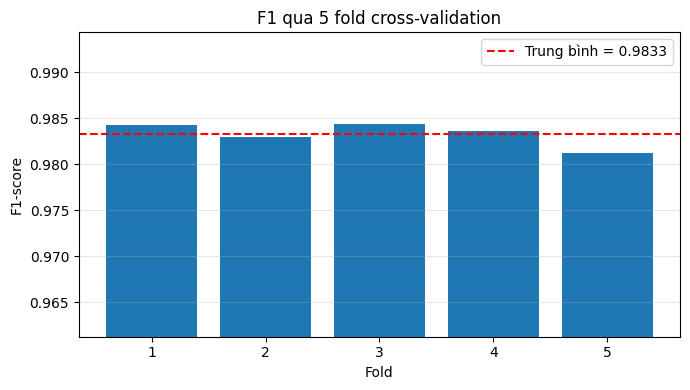

In [11]:
# Toàn bộ chuỗi biến đổi phải nằm TRONG Pipeline để mỗi fold tự fit lại trên
# phần train của riêng nó. Nếu biến đổi trước rồi mới chia fold thì thông tin
# của fold validation đã rò rỉ vào phép biến đổi.
#
# VarianceThreshold đứng đầu pipeline vì trong một fold có thể có đặc trưng
# trở thành hằng số; khi đó Yeo-Johnson không tìm được tham số lambda và báo
# lỗi BracketError.
steps = [("vt", VarianceThreshold())]
steps.append(("tf", PowerTransformer(standardize=True) if REPR == "PowerTransformer"
              else StandardScaler()))
if USE_CF:
    steps.append(("cf", CorrelationFilter(threshold=CORR_THR)))
steps.append(("nb", GaussianNB(var_smoothing=VS_F)))
pipe = Pipeline(steps)
print("Pipeline:", " → ".join(n for n, _ in steps))

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
scores = cross_val_score(pipe, X_raw.values, y, cv=cv, scoring="f1", n_jobs=-1)

print(f"\nF1 từng fold : {np.round(scores, 4)}")
print(f"F1 trung bình: {scores.mean():.4f} ± {scores.std():.4f}")
print(f"F1 của một lần chia train/test ở A7: {nb_res['f1']:.4f}")
print(KFOLD_COMMENT)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(scores) + 1), scores)
ax.axhline(scores.mean(), color="red", ls="--",
           label=f"Trung bình = {scores.mean():.4f}")
ax.set_xlabel("Fold")
ax.set_ylabel("F1-score")
ax.set_ylim(min(scores) - 0.02, max(scores) + 0.01)
ax.set_title(f"F1 qua {CV_FOLDS} fold cross-validation")
ax.legend()
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


---
## Nhận Xét & Câu Hỏi Thảo Luận

**Tổng hợp những gì bài thực hành cho thấy**

1. Với tham số mặc định, `GaussianNB` cho F1 khoảng 0,54 — tệ hơn cả `MultinomialNB` (0,97), dù dữ liệu là số liên tục đúng kiểu mà GaussianNB được thiết kế cho.
2. Nguyên nhân thứ nhất là `var_smoothing`: nâng từ 1e-9 lên 0,01 đưa F1 lên 0,75.
3. Nguyên nhân thứ hai là giả định phân phối chuẩn bị vi phạm nặng — 58/72 đặc trưng có |độ lệch| > 2. `PowerTransformer` đưa F1 lên 0,97.
4. Giả định độc lập điều kiện cũng bị vi phạm: có cặp đặc trưng tương quan đúng 1,0, nhưng loại chúng đi gần như không thay đổi hiệu năng.
5. Hơn 97% mẫu được gán xác suất cực đoan; hiệu chỉnh isotonic giảm Brier từ 0,0341 xuống 0,0232 mà không giảm AUC.
6. Random Forest vẫn cao hơn (F1 0,995 so với 0,975), nhưng Naive Bayes huấn luyện nhanh hơn khoảng hai bậc độ lớn.

**Câu hỏi thảo luận**

1. Về lý thuyết `GaussianNB` bất biến với phép co giãn tuyến tính từng đặc trưng. Hãy giải thích vì sao trên thực tế việc chuẩn hóa Z-score lại thay đổi kết quả, dựa trên công thức cộng thêm phương sai của scikit-learn.
2. So sánh mức cải thiện do dò `var_smoothing` (0,54 → 0,75) với mức cải thiện do `PowerTransformer` (0,75 → 0,97). Rút ra kết luận gì về thứ tự ưu tiên khi cải thiện một mô hình Naive Bayes?
3. `MultinomialNB` giả định đặc trưng là **số đếm không âm**, trong khi dữ liệu ở đây là thống kê lưu lượng đã đưa về khoảng [0, 1]. Vì sao mô hình "sai giả định" này lại cho kết quả tốt ngay từ tham số mặc định?
4. Hãy xem lại phần A5: loại 18 đặc trưng tương quan cao mà hiệu năng không giảm. Điều đó nói gì về lượng thông tin thực sự trong 72 đặc trưng ban đầu?
5. Vì sao ở phần A7 việc chọn tập đặc trưng và chọn ngưỡng phải làm trên tập validation tách từ train, chứ không phải trên tập test? Nếu chọn theo điểm trên tập test thì con số báo cáo cuối cùng sai lệch theo hướng nào?
6. Tinh chỉnh ngưỡng ở bộ dữ liệu này gần như không có tác dụng. Hãy liên hệ với tỷ lệ 97% xác suất cực đoan ở phần A6 để giải thích.
7. Random Forest tốt hơn về mọi chỉ số chất lượng. Trong tình huống thực tế nào bạn vẫn sẽ chọn Naive Bayes cho một hệ thống IDS?
